# Compare the Summaries with the C-SPAN Abstracts

| Item | Description |
|---|---|
| Goal | Test whether each generated summary describes its own hearing. The C-SPAN abstracts are short, a median of 48 words against about 390 tokens for a summary, and say what a hearing was about rather than what was said, so a word-overlap score would mostly measure that gap. The test instead embeds both texts and compares three sets of pairs: the summary against the abstract of the same hearing, against the abstracts of other hearings of the same committee, and against the abstracts of hearings of other committees. A summary that describes its hearing sits closest to its own abstract. |
| Input | `cspan_matches.parquet` from T1.3.1, the 3,812 matches and their abstracts; `hearing_summaries.parquet` from T1.2, the summaries of the 351 matched hearings. The encoder BAAI/bge-large-en-v1.5 from the project cache. |
| Output | In the T1.3 Interim folder: `summary_embeddings.npy`, `abstract_embeddings.npy`, and `summary_abstract_pairs.parquet`, one row per pair with its cosine and pair type. The figure, in PNG, SVG, and PDF, in `R - Results/figures/T1 - Text Summarization/T1.3 - Validation of Summaries/T1.3.2 - Validation - Compare Summaries with C-SPAN Abstracts`. |
| Variables | • `cosine`: cosine similarity of the two embedded texts, CLS-pooled and L2-normalized, so it is their dot product<br>• `pair_type`: `same hearing`, `same committee, other hearing`, or `other committee` |
| Run | First run 2026-08-21 on a GPU; it kept the matches and the figure but not the similarities. Rerun 2026-10-31 on an interactive A40 node with the same encoder, storing the similarities and redrawing the figure (command: `J - Jobs/run_T1.3.2_cspan_similarity.sbatch`; log: `J - Jobs/log/T1.3.2_cspan_similarity_13632230.out`). The outputs shown are from that run; Step 8 checks its numbers against August. |

## Step 1. Import packages

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from transformers import AutoModel, AutoTokenizer

## Step 2. Define file locations

In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[1]  # <section>/<subfolder>/ sits two levels below the clone
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")  # the one line to change on another machine
NOTEBOOK_SUBFOLDER = Path("T1 - Text Summarization/T1.3 - Validation of Summaries")
NOTEBOOK_NAME = "T1.3.2 - Validation - Compare Summaries with C-SPAN Abstracts"
INTERIM_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Interim"
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
SUMMARIES_FOLDER = SCRATCH_FOLDER / "T1 - Text Summarization/T1.2 - Process Entire Sample Congressional Hearings" / "Processed"
FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/figures" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
MODEL_CACHE = SCRATCH_FOLDER / "cache" / "huggingface"

INTERIM_FOLDER.mkdir(parents=True, exist_ok=True)
FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
os.environ["HF_HOME"] = str(MODEL_CACHE)

## Step 3. Apply the figure style

In [3]:
# Colors from the Figure Style Guide
BLACK = "#000000"
DODGER_BLUE = "#1E90FF"
SLATE_GREY = "#708090"
CYAN = "#00ACC1"
GREY = "#A6A6A8"

# Font and background
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True

# Horizontal background lines only
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5

# All text and axis lines in BLACK
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

MARGIN_INCHES = 0.5 / 2.54  # 0.5 cm between each edge of the image and the nearest element

## Step 4. Load the matches and the summaries

The focal side is the 351 matched hearings that have a summary. The comparison pool is every accepted abstract, 3,812 in all, from 47 committees across Congress. So the test is not confined to the two committees the sample holds.

In [4]:
ENCODER = "BAAI/bge-large-en-v1.5"
MAX_LENGTH = 512  # the sequence length the checkpoint declares

matches = pd.read_parquet(PROCESSED_FOLDER / "cspan_matches.parquet")
summaries = pd.read_parquet(SUMMARIES_FOLDER / "hearing_summaries.parquet", columns=["packageId", "summary", "status", "year", "model"])
SUMMARY_MODEL = summaries.loc[summaries["status"].eq("ok"), "model"].unique()[0]

focal = matches.loc[matches["in_sst"]].merge(summaries.loc[summaries["status"].eq("ok"), ["packageId", "summary"]], on="packageId", how="inner").reset_index(drop=True)
print(f"abstracts in the pool : {len(matches):,}")
print(f"summaries, focal side : {len(focal):,}  ({focal['year'].min()}-{focal['year'].max()}), written by {SUMMARY_MODEL}")
print(f"committees in the pool: {len(set().union(*matches['committee_ids'].map(set))):,}")

abstracts in the pool : 3,812
summaries, focal side : 351  (1999-2025), written by Qwen/Qwen3.5-4B
committees in the pool: 47


## Step 5. Embed both sides

The encoder is loaded from the project cache, so the revision is the one of the first run. Each text is CLS-pooled and L2-normalized, the pooling the checkpoint publishes, so every cosine below is a dot product. Summaries run to about 360 tokens and abstracts to about 75, so nothing is truncated at the 512-token limit, and the counts are printed.

In [5]:
@torch.no_grad()
def embed(texts, model, tokenizer, batch_size=64):
    """CLS-pooled, L2-normalized embeddings, one row per text."""
    out = np.empty((len(texts), model.config.hidden_size), dtype=np.float32)
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(texts[start:start + batch_size], padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(model.device)
        vec = model(**batch).last_hidden_state[:, 0]
        vec = torch.nn.functional.normalize(vec, dim=-1)
        out[start:start + len(vec)] = vec.float().cpu().numpy()
    return out


device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(ENCODER)
model = AutoModel.from_pretrained(ENCODER).to(device).eval()

summary_vec = embed(focal["summary"].tolist(), model, tokenizer)
abstract_vec = embed(matches["abstract"].tolist(), model, tokenizer)

n_summary = np.array([len(tokenizer(t)["input_ids"]) for t in focal["summary"]])
n_abstract = np.array([len(tokenizer(t)["input_ids"]) for t in matches["abstract"]])
print(f"{ENCODER} on {device}, {model.config.hidden_size} dimensions, {MAX_LENGTH}-token limit")
print(f"  {len(focal):,} summaries against {len(matches):,} abstracts")
print(f"  summary tokens : median {np.median(n_summary):.0f}, max {n_summary.max()}  -> {(n_summary > MAX_LENGTH).mean():.1%} truncated")
print(f"  abstract tokens: median {np.median(n_abstract):.0f}, max {n_abstract.max()}  -> {(n_abstract > MAX_LENGTH).mean():.1%} truncated")

BAAI/bge-large-en-v1.5 on cuda, 1024 dimensions, 512-token limit
  351 summaries against 3,812 abstracts
  summary tokens : median 362, max 480  -> 0.0% truncated
  abstract tokens: median 74, max 232  -> 0.0% truncated


## Step 6. Save the embeddings

The first run kept neither the embeddings nor the similarities. Both are saved this time, so the figure can be redrawn without the encoder.

In [6]:
np.save(INTERIM_FOLDER / "summary_embeddings.npy", summary_vec)
np.save(INTERIM_FOLDER / "abstract_embeddings.npy", abstract_vec)
focal[["packageId", "cspan_id"]].to_parquet(INTERIM_FOLDER / "summary_embeddings_index.parquet", index=False)
matches[["packageId", "cspan_id"]].to_parquet(INTERIM_FOLDER / "abstract_embeddings_index.parquet", index=False)
print(f"summary embeddings  {summary_vec.shape}  -> {INTERIM_FOLDER / 'summary_embeddings.npy'}")
print(f"abstract embeddings {abstract_vec.shape}  -> {INTERIM_FOLDER / 'abstract_embeddings.npy'}")

summary embeddings  (351, 1024)  -> /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T1 - Text Summarization/T1.3 - Validation of Summaries/Interim/summary_embeddings.npy
abstract embeddings (3812, 1024)  -> /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T1 - Text Summarization/T1.3 - Validation of Summaries/Interim/abstract_embeddings.npy


## Step 7. Compute the cosine for every pair and sort the pairs into three sets

Every summary is compared with every abstract. Two hearings belong to the same committee when their committee identifier lists intersect; the identifier holds across the committee's renames. The three sets tile the grid exactly: every pair falls in one of them and none in two, which the cell asserts.

In [7]:
sims = summary_vec @ abstract_vec.T  # focal x pool

pool_committee = [set(ids) for ids in matches["committee_ids"]]
shares = np.array([[bool(set(a) & b) for b in pool_committee] for a in focal["committee_ids"]])
position = {package: j for j, package in enumerate(matches["packageId"])}
own = np.array([position[p] for p in focal["packageId"]], dtype=int)
is_own = np.zeros_like(shares)
is_own[np.arange(len(focal)), own] = True

PAIR_TYPES = {"same hearing": is_own, "same committee, other hearing": shares & ~is_own, "other committee": ~shares}
assert sum(int(m.sum()) for m in PAIR_TYPES.values()) == sims.size, "the three sets do not partition the grid"
assert not (shares & ~is_own)[np.arange(len(focal)), own].any() and not (~shares)[np.arange(len(focal)), own].any()

for name, mask in PAIR_TYPES.items():
    q1, med, q3 = np.percentile(sims[mask], [25, 50, 75])
    print(f"  {name:<31} n = {int(mask.sum()):>9,}   median {med:.3f}   IQR {q1:.3f}-{q3:.3f}")

nearest_is_own = sims.argmax(axis=1) == own
print(f"\nthe own abstract is the nearest of all {len(matches):,}: {int(nearest_is_own.sum()):,}/{len(focal):,} ({nearest_is_own.mean():.1%})")

# one row per pair, saved for the figure and for any later use
pair_type = np.empty(sims.shape, dtype=object)
for name, mask in PAIR_TYPES.items():
    pair_type[mask] = name
focal_index, pool_index = np.indices(sims.shape)
pairs = pd.DataFrame({
    "packageId": focal["packageId"].to_numpy()[focal_index.ravel()],
    "abstract_packageId": matches["packageId"].to_numpy()[pool_index.ravel()],
    "cspan_id": matches["cspan_id"].to_numpy()[pool_index.ravel()],
    "pair_type": pd.Categorical(pair_type.ravel(), categories=list(PAIR_TYPES)),
    "cosine": sims.ravel().astype(np.float32),
})
pairs.to_parquet(INTERIM_FOLDER / "summary_abstract_pairs.parquet", compression="zstd", index=False)
print(f"wrote {len(pairs):,} pairs -> {INTERIM_FOLDER / 'summary_abstract_pairs.parquet'}")

  same hearing                    n =       351   median 0.798   IQR 0.752-0.837
  same committee, other hearing   n =    94,304   median 0.576   IQR 0.529-0.621
  other committee                 n = 1,243,357   median 0.533   IQR 0.498-0.567

the own abstract is the nearest of all 3,812: 215/351 (61.3%)


wrote 1,338,012 pairs -> /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T1 - Text Summarization/T1.3 - Validation of Summaries/Interim/summary_abstract_pairs.parquet


## Step 8. Compare with the first run

The August run printed its medians and interquartile ranges and the nearest-abstract count. The same encoder on the same texts should reproduce them to the third decimal.

In [8]:
AUGUST = {"same hearing": (0.798, 0.752, 0.837), "same committee, other hearing": (0.576, 0.529, 0.621), "other committee": (0.533, 0.498, 0.567)}
AUGUST_NEAREST = 215

for name, (med_aug, q1_aug, q3_aug) in AUGUST.items():
    q1, med, q3 = np.percentile(sims[PAIR_TYPES[name]], [25, 50, 75])
    gap = max(abs(med - med_aug), abs(q1 - q1_aug), abs(q3 - q3_aug))
    assert gap < 0.005, f"{name}: this run differs from August by {gap:.3f}"
    print(f"{name:<31} August {med_aug:.3f} ({q1_aug:.3f}-{q3_aug:.3f})   now {med:.3f} ({q1:.3f}-{q3:.3f})")
print(f"own abstract nearest: August {AUGUST_NEAREST}/351, now {int(nearest_is_own.sum())}/{len(focal)}")

same hearing                    August 0.798 (0.752-0.837)   now 0.798 (0.752-0.837)
same committee, other hearing   August 0.576 (0.529-0.621)   now 0.576 (0.529-0.621)
other committee                 August 0.533 (0.498-0.567)   now 0.533 (0.498-0.567)
own abstract nearest: August 215/351, now 215/351


## Step 9. Draw the figure

One box per pair type. The matched pairs, summary and abstract of the same hearing, are the claim and are drawn in DODGER_BLUE. The unmatched pairs are in CYAN for the same committee and SLATE_GREY for a different committee. Boxes span the interquartile range and whiskers reach 1.5 times that range; the 1.3 million individual pairs are not drawn. The title, Notes, and Source are printed below the image, not inside it.

**Figure 1. Cosine Similarity Between Hearing Summaries and C-SPAN Abstracts, by Pair Type**

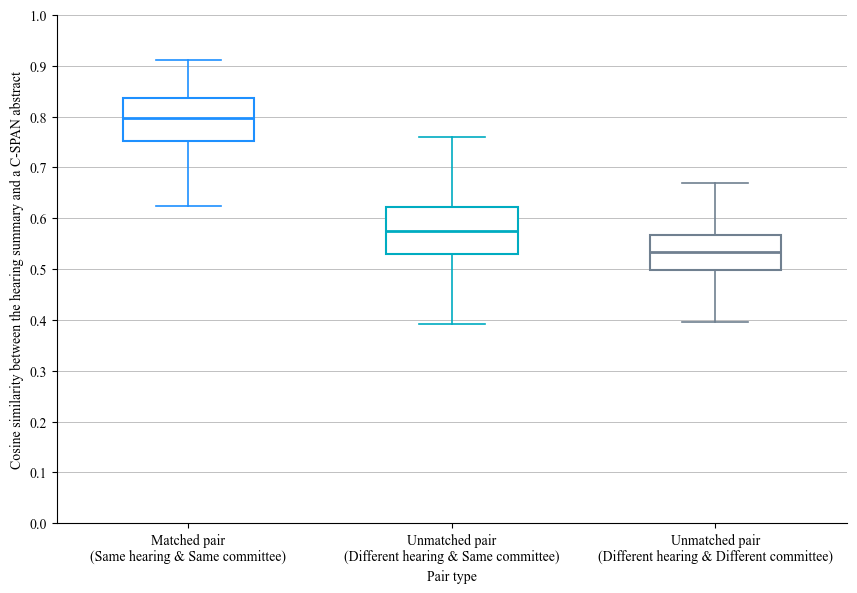

*Notes*: Each observation is one pair, the generated summary of a hearing against one C-SPAN abstract. 351 science-committee hearings of 1999 to 2025, matched to C-SPAN by date, chamber, title, and witnesses, are compared against 3,812 abstracts of hearings of 47 committees. Pairs: matched, same hearing, 351; unmatched, different hearing of the same committee, 94,304; unmatched, different committee, 1,243,357. Boxes span the interquartile range and whiskers reach 1.5 times that range; outliers are not drawn. Summaries written by Qwen/Qwen3.5-4B; embeddings by BAAI/bge-large-en-v1.5 at 512 tokens, no truncation.

*Source*: C-SPAN Video Library program abstracts; congressional hearing transcripts from GovInfo, summarized in T1.2.

saved fig_cosine_similarity_by_pair_type.png/.svg/.pdf in /project2/njia_1089/acroh/projects/OS_LLM_TEMP/R - Results/figures/T1 - Text Summarization/T1.3 - Validation of Summaries/T1.3.2 - Validation - Compare Summaries with C-SPAN Abstracts


In [9]:
FIGURE_STEM = "fig_cosine_similarity_by_pair_type"
values = [sims[mask] for mask in PAIR_TYPES.values()]
labels = ["Matched pair\n(Same hearing & Same committee)", "Unmatched pair\n(Different hearing & Same committee)", "Unmatched pair\n(Different hearing & Different committee)"]
colors = [DODGER_BLUE, CYAN, SLATE_GREY]

fig, axis = plt.subplots()
fig.subplots_adjust(left=0.10, right=1 - MARGIN_INCHES / 9, top=1 - MARGIN_INCHES / 6, bottom=0.12)
boxes = axis.boxplot(values, widths=0.5, patch_artist=True, showfliers=False, zorder=3)
for i, color in enumerate(colors):
    boxes["boxes"][i].set(facecolor="white", edgecolor=color, linewidth=1.5)
    boxes["medians"][i].set(color=color, linewidth=2)
    for part in ("whiskers", "caps"):
        for artist in boxes[part][2 * i:2 * i + 2]:
            artist.set(color=color, linewidth=1.2)
axis.set_xticks([1, 2, 3])
axis.set_xticklabels(labels)
axis.set_ylabel("Cosine similarity between the hearing summary and a C-SPAN abstract")
axis.set_xlabel("Pair type")
axis.set_ylim(0, 1)
axis.set_yticks(np.arange(0, 1.01, 0.1))
for side in ("top", "right"):
    axis.spines[side].set_visible(False)

for extension in ("png", "svg", "pdf"):
    fig.savefig(FIGURE_FOLDER / f"{FIGURE_STEM}.{extension}", dpi=300 if extension == "png" else None)

display(Markdown("**Figure 1. Cosine Similarity Between Hearing Summaries and C-SPAN Abstracts, by Pair Type**"))
plt.show()
n_committees = len(set().union(*matches["committee_ids"].map(set)))
display(Markdown(
    f"*Notes*: Each observation is one pair, the generated summary of a hearing against one C-SPAN abstract. "
    f"{len(focal):,} science-committee hearings of {focal['year'].min()} to {focal['year'].max()}, matched to C-SPAN by date, chamber, title, and witnesses, "
    f"are compared against {len(matches):,} abstracts of hearings of {n_committees:,} committees. "
    f"Pairs: matched, same hearing, {int(PAIR_TYPES['same hearing'].sum()):,}; unmatched, different hearing of the same committee, {int(PAIR_TYPES['same committee, other hearing'].sum()):,}; "
    f"unmatched, different committee, {int(PAIR_TYPES['other committee'].sum()):,}. Boxes span the interquartile range and whiskers reach 1.5 times that range; outliers are not drawn. "
    f"Summaries written by {SUMMARY_MODEL}; embeddings by {ENCODER} at {MAX_LENGTH} tokens, no truncation.\n\n"
    f"*Source*: C-SPAN Video Library program abstracts; congressional hearing transcripts from GovInfo, summarized in T1.2."))
print(f"saved {FIGURE_STEM}.png/.svg/.pdf in {FIGURE_FOLDER}")

## Step 10. Check the run

- Every cosine is finite and within [-1, 1].
- The pair table has one row per summary and abstract.
- The same-hearing median exceeds both comparison medians.
- The saved embeddings reproduce the similarity matrix.

In [10]:
assert np.isfinite(sims).all() and (np.abs(sims) <= 1.001).all(), "a cosine is out of range"
print("1) every cosine is finite and within [-1, 1]")

back = pd.read_parquet(INTERIM_FOLDER / "summary_abstract_pairs.parquet")
assert len(back) == len(focal) * len(matches), f"{len(back):,} pairs against {len(focal) * len(matches):,} expected"
print(f"2) {len(back):,} pairs, one per summary and abstract; by type {back['pair_type'].value_counts().to_dict()}")

medians = {name: float(np.median(sims[mask])) for name, mask in PAIR_TYPES.items()}
assert medians["same hearing"] > max(medians["same committee, other hearing"], medians["other committee"])
print(f"3) same-hearing median {medians['same hearing']:.3f} exceeds {medians['same committee, other hearing']:.3f} and {medians['other committee']:.3f}")

s = np.load(INTERIM_FOLDER / "summary_embeddings.npy"); a = np.load(INTERIM_FOLDER / "abstract_embeddings.npy")
assert np.allclose(s @ a.T, sims, atol=1e-6), "the saved embeddings do not reproduce the similarities"
print("4) the saved embeddings reproduce the similarity matrix")

1) every cosine is finite and within [-1, 1]
2) 1,338,012 pairs, one per summary and abstract; by type {'other committee': 1243357, 'same committee, other hearing': 94304, 'same hearing': 351}
3) same-hearing median 0.798 exceeds 0.576 and 0.533
4) the saved embeddings reproduce the similarity matrix
